# Summary Statistics of data used in the project

This notebook is summary statistics of the data used in this project

First we investigate the raw data

In [1]:
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np 
import os 

CO2_DATA_PATH = "data/raw/dtu/timeseries" 
FEEDBACK_PATH = "data/raw/dtu/feedback"

co2_files = os.listdir(CO2_DATA_PATH) 
co2_files

['Room 008.csv',
 'Room 009.csv',
 'Corridor 073.csv',
 'Room 032.csv',
 'Room 019.csv',
 'Corridor 070.csv',
 'Corridor 071.csv',
 'Office 017.csv',
 'Room 057.csv',
 'Room 056.csv',
 'Room 054.csv',
 'Room 051.csv',
 'Room 045.csv',
 'Room 050.csv',
 'Room 046.csv',
 'Room 052.csv',
 'Room 053.csv',
 'Room 047.csv',
 'Meeting room 034.csv',
 'Class 026.csv',
 'Meeting room 023.csv',
 'Room 061.csv',
 'Room 049.csv',
 'Room 048.csv',
 'Room 060.csv',
 'Room 058.csv',
 'Room 001.csv',
 'Room 015.csv',
 'Room 014.csv',
 'Room 016.csv',
 'Room 003.csv',
 'Office 018.csv',
 'Room 013.csv',
 'Room 007.csv',
 'Room 012.csv',
 'Room 004.csv',
 'Room 010.csv',
 'Room 011.csv',
 'Room 005.csv',
 'Room 039.csv']

In [2]:
co2_files = os.listdir(CO2_DATA_PATH) 

co2_files = [filename for filename in co2_files if "Room" in filename] 

co2_files.sort() 

print(co2_files)

['Room 001.csv', 'Room 003.csv', 'Room 004.csv', 'Room 005.csv', 'Room 007.csv', 'Room 008.csv', 'Room 009.csv', 'Room 010.csv', 'Room 011.csv', 'Room 012.csv', 'Room 013.csv', 'Room 014.csv', 'Room 015.csv', 'Room 016.csv', 'Room 019.csv', 'Room 032.csv', 'Room 039.csv', 'Room 045.csv', 'Room 046.csv', 'Room 047.csv', 'Room 048.csv', 'Room 049.csv', 'Room 050.csv', 'Room 051.csv', 'Room 052.csv', 'Room 053.csv', 'Room 054.csv', 'Room 056.csv', 'Room 057.csv', 'Room 058.csv', 'Room 060.csv', 'Room 061.csv']


In [3]:
def load_df(path: str, filename: str) -> pd.DataFrame: 
    full_path = path + "/" + filename 
    df = pd.read_csv(full_path)
    df["datetime"] = pd.to_datetime(df["datetime"])
    return df


df_dict = {filename: load_df(CO2_DATA_PATH, filename) for filename in co2_files}


In [4]:
def clean_df(df: pd.DataFrame) -> pd.DataFrame:
    return (
        df.drop_duplicates()
        .drop_duplicates(subset="datetime")
        .dropna(subset=["co2"])
        .sort_values("datetime")
        .reset_index(drop=True)
    )


clean_dict = {name: clean_df(df) for name, df in df_dict.items()}

removed = pd.DataFrame(
    {name: {"raw": len(df_dict[name]), "clean": len(clean_dict[name])} for name in co2_files}
).T
removed["removed"] = removed["raw"] - removed["clean"]

removed

,raw,clean,removed
Room 001.csv,23875,14279,9596
Room 003.csv,23925,14327,9598
Room 004.csv,37658,14259,23399
Room 005.csv,14326,14326,0
Room 007.csv,41717,14313,27404
Room 008.csv,23925,14319,9606
Room 009.csv,41424,14327,27097
Room 010.csv,30721,14286,16435
Room 011.csv,23943,14311,9632
Room 012.csv,41760,14319,27441


In [5]:
def load_feedback(path: str, filename: str) -> pd.DataFrame:
    df = pd.read_csv(path + "/" + filename)
    df["datetime"] = pd.to_datetime(df["datetime"])
    return df.drop_duplicates().dropna(subset=["value"])


feedback_dict = {
    filename: load_feedback(FEEDBACK_PATH, filename)
    for filename in sorted(os.listdir(FEEDBACK_PATH))
    if filename in clean_dict
}

# Only keep the rooms that have feedback
clean_dict = {name: clean_dict[name] for name in feedback_dict}

feedback_counts = pd.DataFrame(
    {name: df["value"].value_counts() for name, df in feedback_dict.items()}
).T.fillna(0).astype(int)
feedback_counts.insert(0, "complaints", feedback_counts.sum(axis=1))
display(feedback_counts)

value,complaints,radio_0_opt_0,radio_0_opt_1,radio_0_opt_2,radio_0_opt_3,radio_0_opt_4
Room 001.csv,1,0,1,0,0,0
Room 004.csv,4,0,0,0,4,0
Room 007.csv,16,0,3,8,5,0
Room 009.csv,29,0,5,15,9,0
Room 010.csv,12,0,4,5,3,0
Room 012.csv,16,0,6,10,0,0
Room 015.csv,49,1,11,18,10,9
Room 016.csv,14,0,3,6,5,0
Room 019.csv,37,5,13,17,2,0
Room 039.csv,3,0,2,1,0,0


In [6]:
DEDUP_WINDOW = pd.Timedelta("60min")


def filter_repeat_complaints(df: pd.DataFrame) -> pd.DataFrame:
    """Keep a complaint only if the same user has not made a kept complaint
    in the same category within DEDUP_WINDOW before it."""
    keep = pd.Series(False, index=df.index)
    for _, group in df.sort_values("datetime").groupby(["userId", "value"]):
        last_kept = None
        for idx, t in group["datetime"].items():
            if last_kept is None or t - last_kept > DEDUP_WINDOW:
                keep[idx] = True
                last_kept = t
    return df[keep].sort_values("datetime")


valid_feedback_dict = {name: filter_repeat_complaints(df) for name, df in feedback_dict.items()}

valid_counts = pd.DataFrame(
    {name: df["value"].value_counts() for name, df in valid_feedback_dict.items()}
).T.fillna(0).astype(int)
valid_counts = valid_counts.reindex(columns=feedback_counts.columns.drop("complaints"), fill_value=0)

valid_summary = pd.DataFrame(
    {
        "complaints": feedback_counts["complaints"],
        "valid": valid_counts.sum(axis=1),
    }
)
valid_summary["removed"] = valid_summary["complaints"] - valid_summary["valid"]
valid_summary = valid_summary.join(valid_counts.add_prefix("valid_"))
valid_summary.loc["Total"] = valid_summary.sum()
display(valid_summary)

,complaints,valid,removed,valid_radio_0_opt_0,valid_radio_0_opt_1,valid_radio_0_opt_2,valid_radio_0_opt_3,valid_radio_0_opt_4
Room 001.csv,1,1,0,0,1,0,0,0
Room 004.csv,4,2,2,0,0,0,2,0
Room 007.csv,16,16,0,0,3,8,5,0
Room 009.csv,29,28,1,0,5,15,8,0
Room 010.csv,12,11,1,0,4,5,2,0
Room 012.csv,16,16,0,0,6,10,0,0
Room 015.csv,49,38,11,1,9,17,8,3
Room 016.csv,14,14,0,0,3,6,5,0
Room 019.csv,37,35,2,5,12,16,2,0
Room 039.csv,3,3,0,0,2,1,0,0


In [7]:
QUANTILES = [0.025, 0.25, 0.5, 0.75, 0.975]

def summarise(co2: pd.Series) -> pd.Series:
    q = co2.quantile(QUANTILES)
    q.index = [f"{p:.1%}" for p in QUANTILES]
    return pd.concat([pd.Series({"count": co2.count(), "min": co2.min()}), q,
                      pd.Series({"mean": co2.mean(), "max": co2.max()})])


summary = pd.DataFrame({name: summarise(df["co2"]) for name, df in clean_dict.items()}).T
summary = summary.join(feedback_counts)
display(summary.round(1))

,count,min,2.5%,25.0%,50.0%,75.0%,97.5%,mean,max,complaints,radio_0_opt_0,radio_0_opt_1,radio_0_opt_2,radio_0_opt_3,radio_0_opt_4
Room 001.csv,14279.0,341.0,426.0,517.0,621.0,897.0,2414.1,829.4,5651.0,1,0,1,0,0,0
Room 004.csv,14259.0,292.0,400.0,574.0,941.0,1686.0,3045.5,1202.4,5651.0,4,0,0,0,4,0
Room 007.csv,14313.0,360.0,414.0,486.0,633.0,868.0,1590.0,737.8,5651.0,16,0,3,8,5,0
Room 009.csv,14327.0,325.0,417.0,528.0,686.0,1219.0,2326.9,935.9,5651.0,29,0,5,15,9,0
Room 010.csv,14286.0,343.0,441.0,612.0,923.5,1472.0,2632.5,1109.1,5651.0,12,0,4,5,3,0
Room 012.csv,14319.0,335.0,414.0,508.0,739.0,958.0,1407.0,770.9,5651.0,16,0,6,10,0,0
Room 015.csv,14336.0,337.0,414.0,522.0,755.0,1247.0,2710.6,987.0,5651.0,49,1,11,18,10,9
Room 016.csv,14320.0,349.0,422.0,504.0,686.0,1046.0,1843.0,833.6,5651.0,14,0,3,6,5,0
Room 019.csv,14318.0,355.0,435.0,531.0,727.0,1158.8,1928.0,887.4,5651.0,37,5,13,17,2,0
Room 039.csv,13797.0,352.0,413.0,497.0,598.0,791.0,1272.0,678.0,5651.0,3,0,2,1,0,0


In [8]:
# Waiting time (in minutes) between consecutive observations
wait_summary = pd.DataFrame(
    {name: summarise(df["datetime"].diff().dropna().dt.total_seconds() ) for name, df in clean_dict.items()}
).T
display(wait_summary.round(1))

,count,min,2.5%,25.0%,50.0%,75.0%,97.5%,mean,max
Room 001.csv,14278.0,17.0,584.0,602.0,603.0,606.0,620.0,608.4,4835.0
Room 004.csv,14258.0,33.0,584.0,602.0,604.0,607.0,622.0,609.3,4853.0
Room 007.csv,14312.0,34.0,584.0,602.0,603.0,606.0,619.0,607.0,5359.0
Room 009.csv,14326.0,35.0,584.0,602.0,603.0,606.0,621.0,606.4,9066.0
Room 010.csv,14285.0,17.0,585.0,602.0,604.0,607.0,622.0,608.1,7257.0
Room 012.csv,14318.0,33.0,575.0,602.0,603.0,606.0,620.0,606.7,6626.0
Room 015.csv,14335.0,8.0,575.0,602.0,603.0,606.0,620.0,606.0,6631.0
Room 016.csv,14319.0,34.0,575.0,602.0,603.0,606.0,620.0,606.7,5424.0
Room 019.csv,14317.0,36.0,575.0,602.0,603.0,606.0,620.0,606.8,4853.0
Room 039.csv,13796.0,20.0,585.0,602.0,603.0,608.0,1205.0,629.7,5483.0


Room 015.csv: 3 of 4827 bins missing (0.1%) in 1 gaps


/var/folders/6x/jpylqzgs1yq2q_xtb9dv1lym0000gn/T/ipykernel_19398/2256600296.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(gaps.sort_values("bins", ascending=False).head(10).round(1))


,start,end,bins,duration,co2_before,co2_after
co2,,,,,,
2,2023-11-13 02:30:00,2023-11-13 03:30:00,3,0 days 01:30:00,372.0,369.0


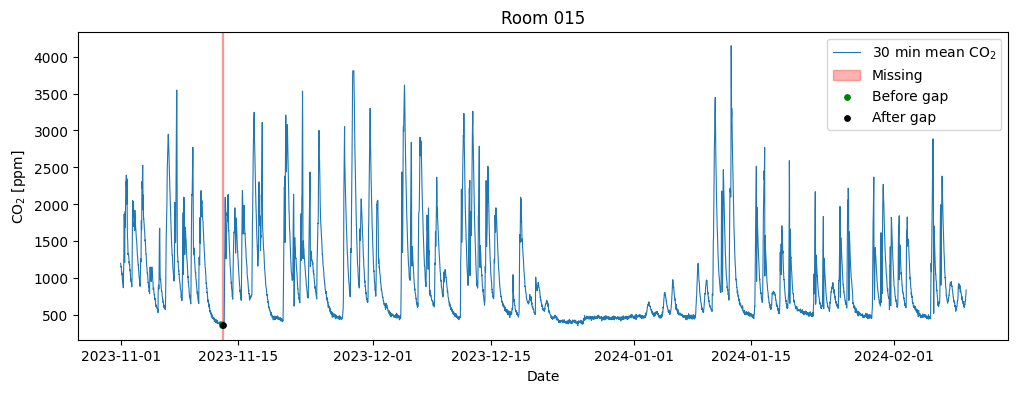

In [9]:
GAP_ROOM = "Room 015.csv"
STEP_GAP = pd.Timedelta("30min")

binned = clean_dict[GAP_ROOM].set_index("datetime")["co2"].resample("30min").mean()
missing = binned.isna()

# Group consecutive missing bins into gaps
gap_id = (missing != missing.shift()).cumsum()[missing]
gaps = binned.index.to_series()[missing].groupby(gap_id).agg(start="first", end="last")
gaps["bins"] = gap_id.groupby(gap_id).size()
gaps["duration"] = gaps["end"] - gaps["start"] + STEP_GAP

# CO2 level in the bin just before and just after each gap
gaps["co2_before"] = binned.shift(1).loc[gaps["start"]].values
gaps["co2_after"] = binned.shift(-1).loc[gaps["end"]].values

print(f"{GAP_ROOM}: {missing.sum()} of {len(binned)} bins missing ({missing.mean():.1%}) in {len(gaps)} gaps")
display(gaps.sort_values("bins", ascending=False).head(10).round(1))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(binned, lw=0.8, label="30 min mean CO$_2$")
for i, (_, g) in enumerate(gaps.iterrows()):
    ax.axvspan(g["start"], g["end"] + STEP_GAP, color="red", alpha=0.3,
               label="Missing" if i == 0 else None)
ax.scatter(gaps["start"] - STEP_GAP, gaps["co2_before"], s=15, color="green", zorder=3, label="Before gap")
ax.scatter(gaps["end"] + STEP_GAP, gaps["co2_after"], s=15, color="black", zorder=3, label="After gap")
ax.set(title=GAP_ROOM.removesuffix(".csv"), xlabel="Date", ylabel="CO$_2$ [ppm]")
ax.legend()
plt.show()

In [10]:
STEP = pd.Timedelta("30min")


def longest_complete_run(df: pd.DataFrame) -> pd.DataFrame:
    """Resample to 30 min means and keep the longest stretch without NaN bins."""
    resampled = df.set_index("datetime")["co2"].resample(STEP).mean()
    valid = resampled.notna()
    run_id = (~valid).cumsum()  # constant within each NaN-free stretch
    run_id = run_id[valid]
    longest = run_id.value_counts().idxmax()
    return resampled[valid][run_id == longest].rename("co2").reset_index()


resampled_list = [longest_complete_run(df) for df in clean_dict.values()]
resampled_dict = dict(zip(clean_dict, resampled_list))

rows = {}
for name, df in resampled_dict.items():
    start, end = df["datetime"].iloc[0], df["datetime"].iloc[-1]
    complaints = feedback_dict[name]["datetime"]
    valid_complaints = valid_feedback_dict[name]["datetime"]
    in_window = lambda t: ((t >= start) & (t < end + STEP)).sum()
    raw_times = clean_dict[name]["datetime"]
    rows[name] = {
        "start": start,
        "end": end,
        "observations": len(df),
        "complaints": in_window(complaints),
        "valid_complaints": in_window(valid_complaints),
        "removed": len(raw_times) - in_window(raw_times),
    }

resampled_summary = pd.DataFrame(rows).T
display(resampled_summary)

,start,end,observations,complaints,valid_complaints,removed
Room 001.csv,2023-11-13 04:00:00,2024-02-09 09:00:00,4235,1,1,1733
Room 004.csv,2023-11-13 04:30:00,2024-02-09 13:00:00,4242,2,1,1717
Room 007.csv,2023-11-13 04:00:00,2024-02-09 13:00:00,4243,14,14,1724
Room 009.csv,2023-11-13 03:30:00,2024-02-09 13:00:00,4244,27,26,1714
Room 010.csv,2023-11-13 03:00:00,2024-02-09 13:00:00,4245,11,10,1717
Room 012.csv,2023-11-13 04:00:00,2024-02-09 13:00:00,4243,16,16,1722
Room 015.csv,2023-11-13 04:00:00,2024-02-09 13:00:00,4243,49,38,1721
Room 016.csv,2023-11-13 04:00:00,2024-02-09 13:00:00,4243,14,14,1719
Room 019.csv,2023-11-13 02:30:00,2024-02-09 13:00:00,4246,37,35,1721
Room 039.csv,2023-11-14 00:00:00,2024-02-01 16:00:00,3825,3,3,2871


Room 015.csv: interpolated 3 of 4827 bins (0.1%), 0 NaN left


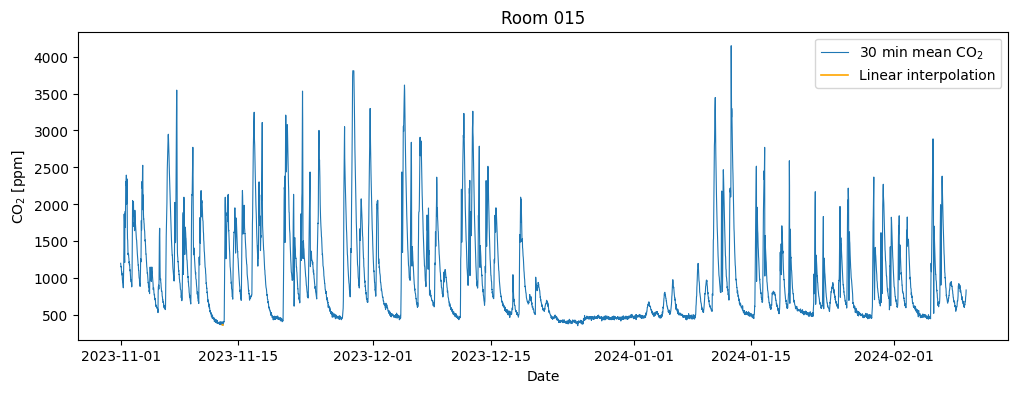

In [11]:
interpolated = binned.interpolate(method="linear")
filled = binned.isna()

print(f"{GAP_ROOM}: interpolated {filled.sum()} of {len(binned)} bins ({filled.mean():.1%}), "
      f"{interpolated.isna().sum()} NaN left")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(binned, lw=0.8, label="30 min mean CO$_2$")
ax.plot(interpolated.where(filled | filled.shift(1, fill_value=False) | filled.shift(-1, fill_value=False)),
        lw=1.2, color="orange", label="Linear interpolation")
ax.set(title=GAP_ROOM.removesuffix(".csv"), xlabel="Date", ylabel="CO$_2$ [ppm]")
ax.legend()
plt.show()

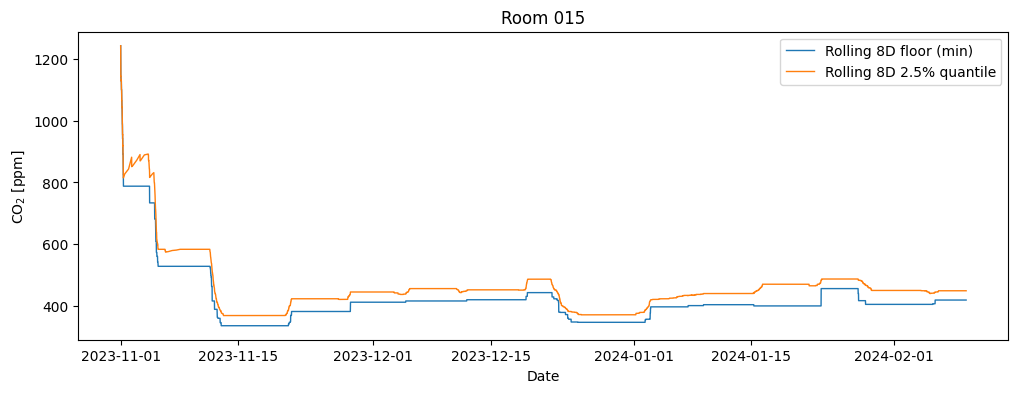

In [12]:
ROOM_STR = "015"
ROOM = f"Room {ROOM_STR}.csv"
WINDOW = "8D"  # trailing window: the 8 days up to and including each observation

co2 = clean_dict[ROOM].set_index("datetime")["co2"]
rolling = co2.rolling(WINDOW)
floor = rolling.min()
q025 = rolling.quantile(0.015)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(floor, label=f"Rolling {WINDOW} floor (min)", lw=1)
ax.plot(q025, label=f"Rolling {WINDOW} 2.5% quantile", lw=1)
ax.set(title=ROOM.removesuffix(".csv"), xlabel="Date", ylabel="CO$_2$ [ppm]")
ax.legend()
plt.show()

By doing a 2.5% quantile trailing of the last 8 days, we see a much more smooth line over the floor

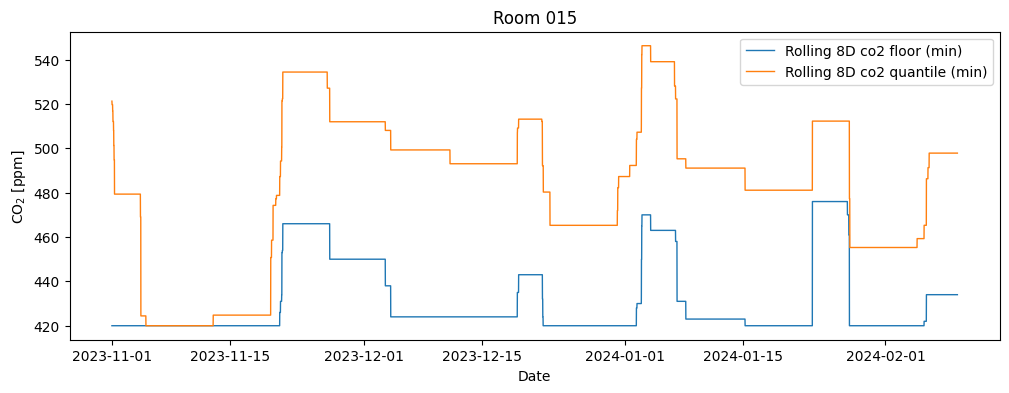

In [13]:
OUTSIDE_CO2 = 420 

co2_floor = co2 - floor + OUTSIDE_CO2 
co2_quantile = co2 - q025 + (OUTSIDE_CO2 - np.asarray(co2 - q025).min())

co2_floor_min = co2_floor.rolling(WINDOW).min()
co2_quantile_min = co2_quantile.rolling(WINDOW).min()




fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(co2_floor_min, label=f"Rolling {WINDOW} co2 floor (min)", lw=1)
ax.plot(co2_quantile_min, label=f"Rolling {WINDOW} co2 quantile (min)", lw=1)
ax.set(title=ROOM.removesuffix(".csv"), xlabel="Date", ylabel="CO$_2$ [ppm]")
ax.legend()
plt.show()


We see know that we have a bit moore step wise function of the CO2 data, but the generel trend is that its much higher than normal. This gives us a good indication that a CO2 level of 530 actuallu means a empty room due to the way the building works

### 

## Cleaned data

We know clean room 15

In [14]:
co2_q = co2_quantile 

binned = co2_q.resample("30min").mean()
co2_bin =  binned.interpolate(method="linear")

print(f"Co2 contains NaN vals? {len(co2_bin[co2_bin.isna()]) > 0}") 

Co2 contains NaN vals? False


## Temporal Structure

In [32]:
import statsmodels.api as sm 
import statsmodels.formula.api as smf
from statsmodels.tsa.ar_model import AutoReg

mod = AutoReg(co2_bin, 1)
res = mod.fit()
print(res.summary())

                            AutoReg Model Results                             
Dep. Variable:                    co2   No. Observations:                 4827
Model:                     AutoReg(1)   Log Likelihood              -30575.776
Method:               Conditional MLE   S.D. of innovations            136.551
Date:                Thu, 12 Nov 2026   AIC                          61157.552
Time:                        13:09:23   BIC                          61176.997
Sample:                    11-01-2023   HQIC                         61164.379
                         - 02-09-2024                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         26.6067      3.896      6.830      0.000      18.971      34.242
co2.L1         0.9746      0.003    302.894      0.000       0.968       0.981
                                    Roots           

[]

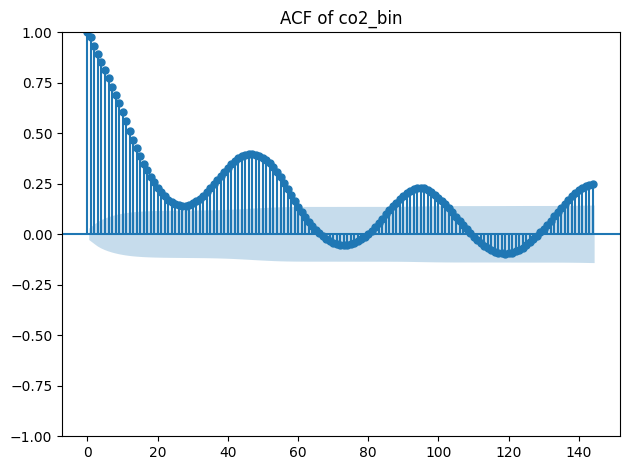

In [28]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

ACF_LAGS = 48 * 3  # three days of 30 min bins
PACF_LAGS = 5

#fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
plot_acf(co2_bin, lags=ACF_LAGS, title="ACF of co2_bin")
plt.tight_layout()
plt.plot()

In [29]:
45*30 / 60

22.5

[]

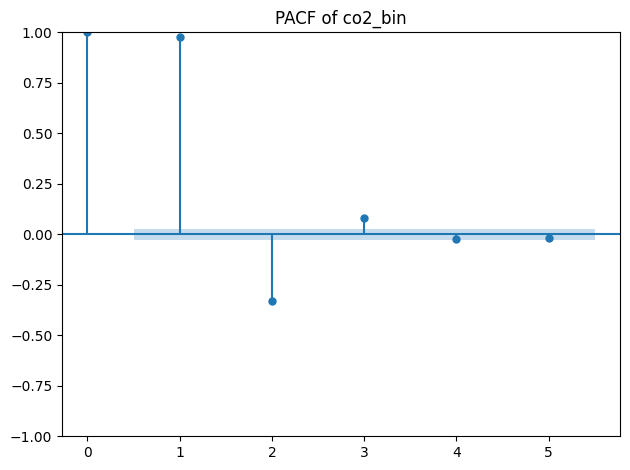

In [30]:
plot_pacf(co2_bin, lags=PACF_LAGS, title="PACF of co2_bin")
plt.tight_layout()
plt.plot()

We clearly see autocorrelation in the data

### We plot IQR values

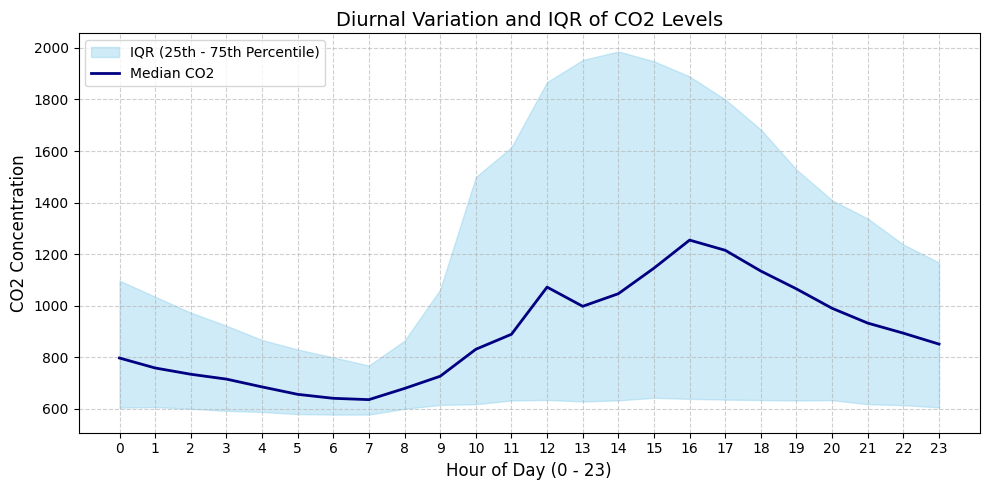

In [19]:

# Assuming 'co2_bin' is your pandas Series with a DatetimeIndex
# Extract the hour from the datetime index
hours = co2_bin.index.hour

# Group by hour and compute median, 25th percentile (Q1), and 75th percentile (Q3)
grouped = co2_bin.groupby(hours)
median = grouped.median()
q25 = grouped.quantile(0.25)
q75 = grouped.quantile(0.75)

# Create the plot
plt.figure(figsize=(10, 5))

# Plot the IQR shaded band
plt.fill_between(
    median.index,
    q25,
    q75,
    color="skyblue",
    alpha=0.4,
    label="IQR (25th - 75th Percentile)",
)

# Plot the median line
plt.plot(median.index, median, color="navy", lw=2, label="Median CO2")

# Styling the plot
plt.title("Diurnal Variation and IQR of CO2 Levels", fontsize=14)
plt.xlabel("Hour of Day (0 - 23)", fontsize=12)
plt.ylabel("CO2 Concentration", fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()

plt.show()

We know check how working days effect the plots

Off days: 34 of 101 days


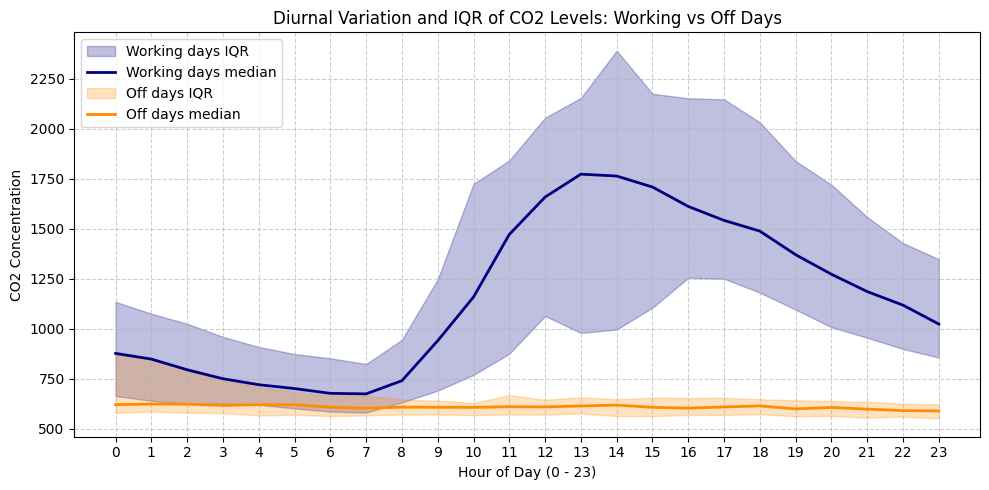

In [20]:
HOLIDAY_PATH = "data/raw/dtu"


def load_holidays(path: str, year: int) -> pd.DatetimeIndex:
    df = pd.read_excel(f"{path}/holidays_{year}.xlsx", skiprows=1)
    df.columns = df.columns.str.strip()
    return pd.DatetimeIndex(df["DATE"]).normalize()


holidays = load_holidays(HOLIDAY_PATH, 2023).union(load_holidays(HOLIDAY_PATH, 2024))
# Treat the whole Christmas break (24/12 - 01/01) as off days
holidays = holidays.union(pd.date_range("2023-12-24", "2024-01-01", freq="D"))

days = co2_bin.index.normalize()
off_day = (co2_bin.index.dayofweek >= 5) | days.isin(holidays)  # Saturday = 5, Sunday = 6

print(f"Off days: {days[off_day].nunique()} of {days.nunique()} days")

fig, ax = plt.subplots(figsize=(10, 5))
for label, mask, color in [("Working days", ~off_day, "navy"), ("Off days", off_day, "darkorange")]:
    grouped = co2_bin[mask].groupby(co2_bin.index.hour[mask])
    median = grouped.median()
    ax.fill_between(median.index, grouped.quantile(0.25), grouped.quantile(0.75),
                    color=color, alpha=0.25, label=f"{label} IQR")
    ax.plot(median.index, median, color=color, lw=2, label=f"{label} median")

ax.set(title="Diurnal Variation and IQR of CO2 Levels: Working vs Off Days",
       xlabel="Hour of Day (0 - 23)", ylabel="CO2 Concentration", xticks=range(0, 24))
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

50% of the middel of the observations mass do not overlap. This arguments for that there is clear correlation between CO2 and if its an off day or working day. This also motivates the idea that co2 levels is only dependent if there is people in the room

### Morning rise before vs after a cutoff
If the clock in the data shifted (e.g. a change to/from winter time), the morning CO2 rise would jump by about 1 hour. Note that the data covers 1 Nov 2023 to 9 Feb 2024, and winter time started on 29 Oct 2023, so there is no daylight-saving change inside the data. We therefore compare before and after the Christmas break; change `CUTOFF` to test another date.

Median rise time before: 9.00 h (32 days), after: 9.50 h (25 days), Mann-Whitney p = 0.004


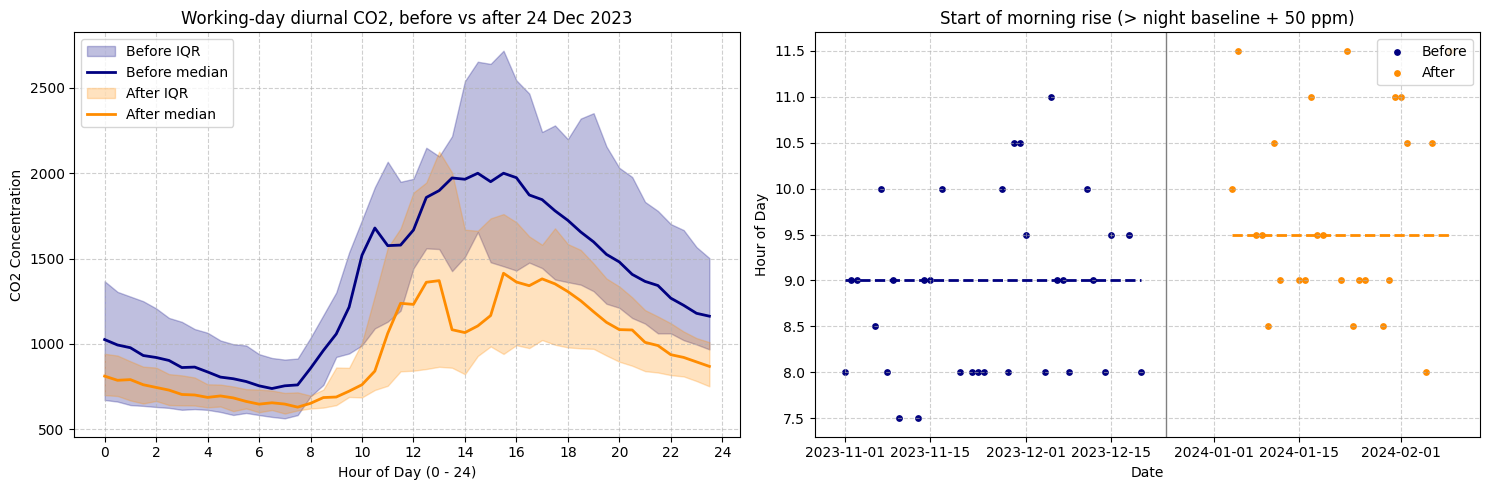

In [21]:
from scipy.stats import mannwhitneyu

# A shift in the clock (e.g. a daylight-saving change) would show up as a jump in when the
# morning CO2 rise starts. Compare working days before and after CUTOFF.
CUTOFF = pd.Timestamp("2023-12-24")  # start of the Christmas break
RISE_PPM = 50  # rise above the night baseline that marks people arriving


def morning_rise(day: pd.Series) -> float:
    """Hour of day at which CO2 first exceeds the night baseline (02-05) by RISE_PPM."""
    night = day.between_time("02:00", "05:00").median()
    morning = day.between_time("05:00", "12:00")
    above = morning[morning > night + RISE_PPM]
    return np.nan if above.empty else above.index[0].hour + above.index[0].minute / 60


work = co2_bin[~off_day]
rise = work.groupby(work.index.normalize()).apply(morning_rise).dropna()
before, after = rise[rise.index < CUTOFF], rise[rise.index >= CUTOFF]

test = mannwhitneyu(before, after)
print(f"Median rise time before: {before.median():.2f} h ({len(before)} days), "
      f"after: {after.median():.2f} h ({len(after)} days), Mann-Whitney p = {test.pvalue:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: diurnal profile of working days in each period
ax = axes[0]
for label, mask, color in [("Before", work.index < CUTOFF, "navy"), ("After", work.index >= CUTOFF, "darkorange")]:
    period = work[mask]
    grouped = period.groupby(period.index.hour + period.index.minute / 60)
    median = grouped.median()
    ax.fill_between(median.index, grouped.quantile(0.25), grouped.quantile(0.75),
                    color=color, alpha=0.25, label=f"{label} IQR")
    ax.plot(median.index, median, color=color, lw=2, label=f"{label} median")
ax.set(title=f"Working-day diurnal CO2, before vs after {CUTOFF:%d %b %Y}",
       xlabel="Hour of Day (0 - 24)", ylabel="CO2 Concentration", xticks=range(0, 25, 2))
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper left")

# Right: time of the morning rise for every working day
ax = axes[1]
ax.scatter(before.index, before, s=15, color="navy", label="Before")
ax.scatter(after.index, after, s=15, color="darkorange", label="After")
for period, color in [(before, "navy"), (after, "darkorange")]:
    ax.hlines(period.median(), period.index[0], period.index[-1], color=color, lw=2, ls="--")
ax.axvline(CUTOFF, color="grey", lw=1)
ax.set(title=f"Start of morning rise (> night baseline + {RISE_PPM} ppm)",
       xlabel="Date", ylabel="Hour of Day")
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

We now look at a normal week, where the only off days are in the weekend (weeks containing a holiday are left out)

Normal weeks: 10 of 15 weeks


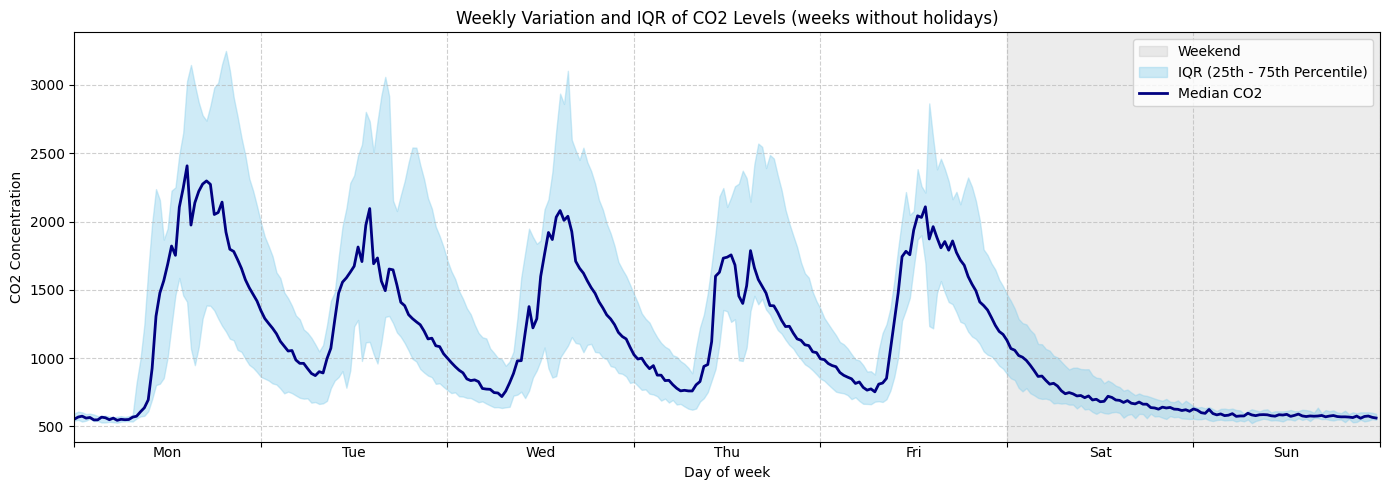

In [22]:
# A normal week: keep only complete Mon-Sun weeks without holidays, so the weekend is the only off time
week = co2_bin.index.to_period("W-SUN")
complete = pd.Series(week).map(pd.Series(week).value_counts()).to_numpy() == 7 * 48
normal_week = ~week.isin(holidays.to_period("W-SUN")) & complete
normal = co2_bin[normal_week]

print(f"Normal weeks: {week[normal_week].nunique()} of {week.nunique()} weeks")

# Position in the week in hours (Monday 00:00 = 0), at 30 min resolution
hour_of_week = normal.index.dayofweek * 24 + normal.index.hour + normal.index.minute / 60
grouped = normal.groupby(hour_of_week)
median = grouped.median()

fig, ax = plt.subplots(figsize=(14, 5))
ax.axvspan(5 * 24, 7 * 24, color="grey", alpha=0.15, label="Weekend")
ax.fill_between(median.index, grouped.quantile(0.15), grouped.quantile(0.85),
                color="skyblue", alpha=0.4, label="IQR (25th - 75th Percentile)")
ax.plot(median.index, median, color="navy", lw=2, label="Median CO2")

ax.set(title="Weekly Variation and IQR of CO2 Levels (weeks without holidays)",
       xlabel="Day of week", ylabel="CO2 Concentration", xlim=(0, 7 * 24))
# Day boundaries as gridlines, day names centred at noon
ax.set_xticks(range(0, 7 * 24 + 1, 24), labels=[])
ax.set_xticks(range(12, 7 * 24, 24), labels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], minor=True)
ax.tick_params(axis="x", which="minor", length=0)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### Covariates

We have already defined 1 covariates, which is off days (weekend and holidays), but we can hypothese that the working hours, 8:00 to 17:00 would be important as well. Typical we would also look at cos and sin of the day or week. 

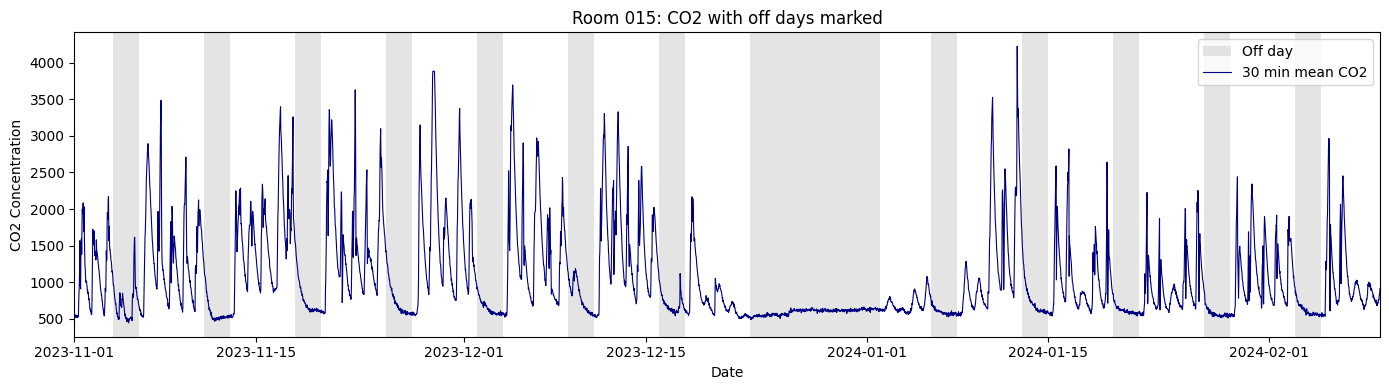

In [23]:
# Full binned series with every off day (weekend or holiday) shaded
off_dates = days[off_day].unique()

fig, ax = plt.subplots(figsize=(14, 4))
for i, d in enumerate(off_dates):
    ax.axvspan(d, d + pd.Timedelta("1D"), color="lightgrey", alpha=0.6, lw=0,
               label="Off day" if i == 0 else None)
ax.plot(co2_bin, color="navy", lw=0.8, label="30 min mean CO2")
ax.set(title=f"{ROOM.removesuffix('.csv')}: CO2 with off days marked",
       xlabel="Date", ylabel="CO2 Concentration", xlim=(co2_bin.index[0], co2_bin.index[-1]))
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

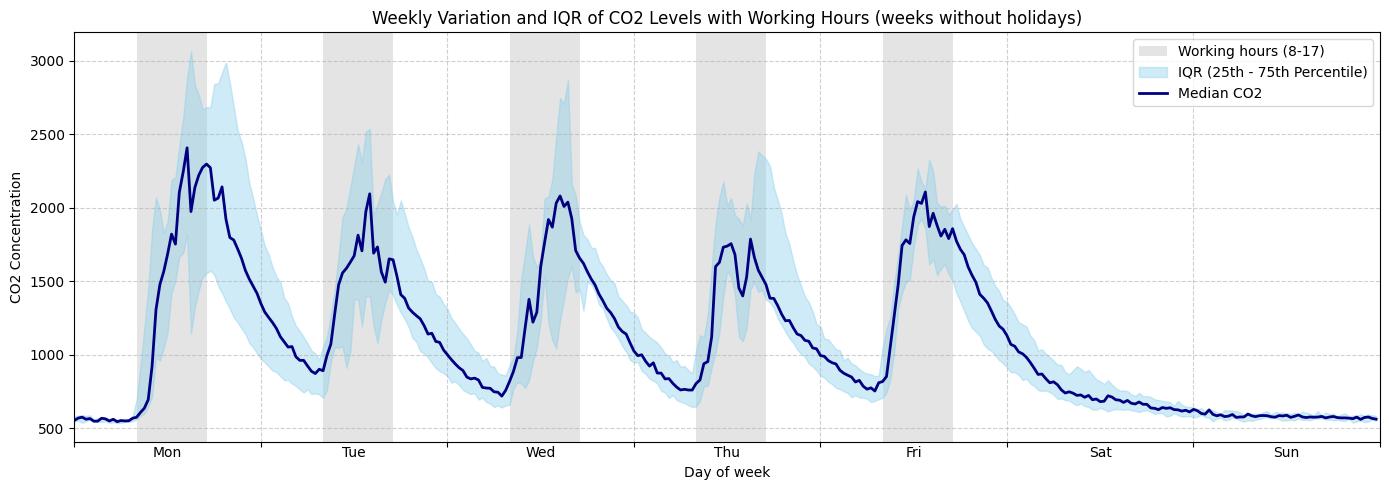

In [24]:
WORK_START, WORK_END = 8, 17

hour_of_week = normal.index.dayofweek * 24 + normal.index.hour + normal.index.minute / 60
grouped = normal.groupby(hour_of_week)
median = grouped.median()

fig, ax = plt.subplots(figsize=(14, 5))
for day in range(5):  # Monday to Friday
    ax.axvspan(day * 24 + WORK_START, day * 24 + WORK_END, color="lightgrey", alpha=0.6, lw=0,
               label=f"Working hours ({WORK_START}-{WORK_END})" if day == 0 else None)
ax.fill_between(median.index, grouped.quantile(0.25), grouped.quantile(0.75),
                color="skyblue", alpha=0.4, label="IQR (25th - 75th Percentile)")
ax.plot(median.index, median, color="navy", lw=2, label="Median CO2")

ax.set(title="Weekly Variation and IQR of CO2 Levels with Working Hours (weeks without holidays)",
       xlabel="Day of week", ylabel="CO2 Concentration", xlim=(0, 7 * 24))
# Day boundaries as gridlines, day names centred at noon
ax.set_xticks(range(0, 7 * 24 + 1, 24), labels=[])
ax.set_xticks(range(12, 7 * 24, 24), labels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], minor=True)
ax.tick_params(axis="x", which="minor", length=0)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

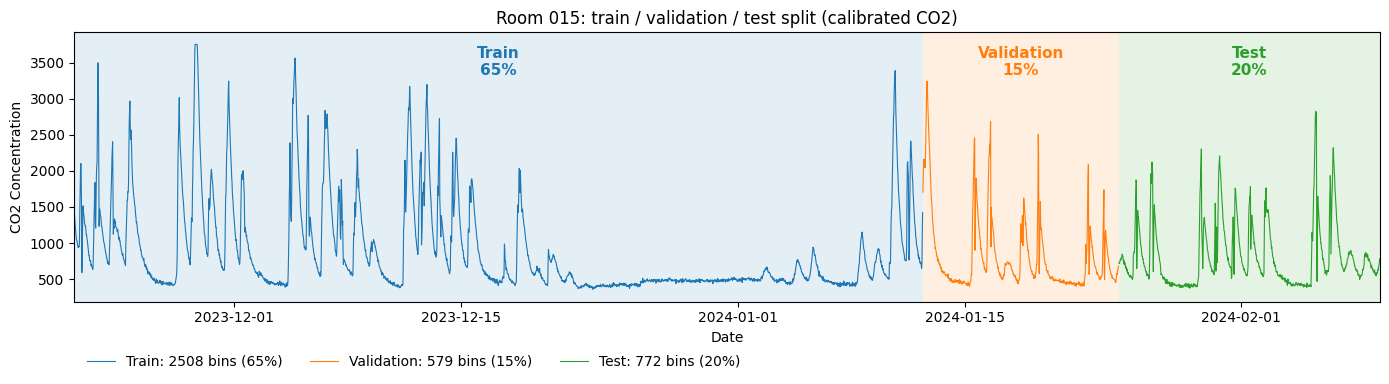

In [25]:
# Train / validation / test split as written by drivers/data/clean_dtu_data.py (chronological 65/15/20)
SPLIT_PATH = f"data/room_{ROOM_STR}/30min"
SPLITS = [("train", "Train", "tab:blue"), ("val", "Validation", "tab:orange"), ("test", "Test", "tab:green")]

split_dict = {
    key: pd.read_csv(f"{SPLIT_PATH}/y_{key}.csv", parse_dates=["datetime"]).set_index("datetime")["co2"]
    for key, _, _ in SPLITS
}
n_total = sum(len(s) for s in split_dict.values())

fig, ax = plt.subplots(figsize=(14, 4))
for key, label, color in SPLITS:
    s = split_dict[key]
    share = len(s) / n_total
    ax.axvspan(s.index[0], s.index[-1] + STEP, color=color, alpha=0.12, lw=0)
    ax.plot(s, color=color, lw=0.8, label=f"{label}: {len(s)} bins ({share:.0%})")
    ax.text(s.index[0] + (s.index[-1] - s.index[0]) / 2, 0.95, f"{label}\n{share:.0%}",
            transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=11,
            fontweight="bold", color=color)

ax.set(title=f"{ROOM.removesuffix('.csv')}: train / validation / test split (calibrated CO2)",
       xlabel="Date", ylabel="CO2 Concentration",
       xlim=(split_dict["train"].index[0], split_dict["test"].index[-1] + STEP))
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

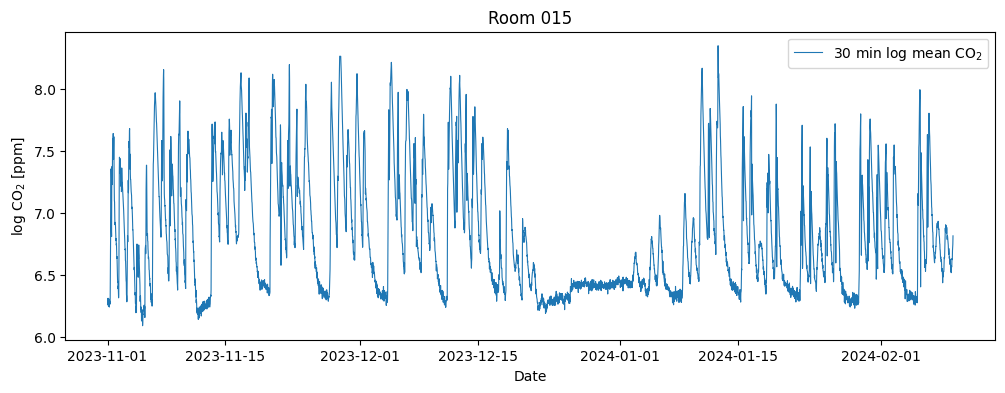

In [26]:

log_co2 = np.log(co2_bin)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(log_co2, lw=0.8, label="30 min log mean CO$_2$")
#ax.plot(log_co2, color="orange", label="Linear interpolation")
ax.set(title=GAP_ROOM.removesuffix(".csv"), xlabel="Date", ylabel="log CO$_2$ [ppm]")
ax.legend()
plt.show()